## Make averages of SST, Chl for each season
### Model

In [1]:
import os
from glob import glob
from collections import OrderedDict
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import pop_tools 
from statistics import mean
from matplotlib import style
import matplotlib
from scipy import stats

### Get CESM model grid info

In [2]:
### First, get the pop grid information, so we have lon, lat
ds_grid = pop_tools.get_grid('POP_gx1v7')
lats = ds_grid.TLAT
lons = ds_grid.TLONG

### Read in CESM SST and Chl

In [3]:
def preprocess(ds):
    ds = ds.isel(z_t=0)
    ds = ds.isel(z_t_150m=0)
    return ds

In [4]:
case = 'g.e22.GOMIPECOIAF_JRA-1p4-2018.TL319_g17.4p2z.002branch'
path = '/glade/campaign/cesm/development/bgcwg/projects/CESM2-OMIP2-like-4p2z-run/'+case+'/ocn/proc/tseries/month_1/'
variables = ['IFRAC','diatChl','spChl','coccoChl','diazChl','TEMP']

ds = xr.Dataset()

for var in variables:
    
    print('starting on ', var)
    ################ FOSI
    
    #ds_tmp = xr.open_dataset(path+case+'.pop.h.'+var+'.??????-??????.nc')
    #ds_tmp['time'] = time
    
    files = sorted(glob(f'{path}/{case}.pop.h.{var}.??????-??????.nc'))       
    ds_tmp = xr.open_mfdataset(files, data_vars="minimal", coords='minimal', compat="override", parallel=True, concat_dim="time",
                       drop_variables=["transport_components", "transport_regions"], decode_times=True, preprocess=preprocess, combine='nested')

    keep_vars=['z_t','z_t_150m','time_bound','dz','TLAT','TLONG','time','KMT'] + [var]

    ds_tmp = ds_tmp.drop_vars([v for v in ds_tmp.variables if v not in keep_vars])
        
    ds = xr.merge([ds,ds_tmp])

starting on  IFRAC
starting on  diatChl
starting on  spChl
starting on  coccoChl
starting on  diazChl
starting on  TEMP


In [5]:
### sum up pft chl, then drop those vars

ds['Chl'] = ds.diatChl + ds.coccoChl + ds.spChl + ds.diazChl

ds = ds.drop_vars(['diatChl','coccoChl','spChl','diazChl'])

### Trim to the same time period as the observations: 2003 (incl Dec 2002 in first DJF) to 2021

In [6]:
ds['time'] = ds.time_bound.compute().mean(dim="d2")

In [7]:
ds['time'][539]

<xarray.DataArray 'time' ()>
array(cftime.DatetimeNoLeap(2002, 12, 16, 12, 0, 0, 0, has_year_zero=True),
      dtype=object)
Coordinates:
    time      object 2002-12-16 12:00:00
    z_t       float32 500.0
    z_t_150m  float32 500.0

In [8]:
ds = ds.isel(time=slice(539,768))

### Now make seasonal averages: : DJF, MAM, JJA, SON

In [9]:
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
#starting with Jan, list of days in each month
days_per_month = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

In [10]:
ds_DJF = xr.Dataset()
ds_MAM = xr.Dataset()
ds_JJA = xr.Dataset()
ds_SON = xr.Dataset()

In [11]:
ds #.time[0]

<xarray.Dataset>
Dimensions:     (time: 229, nlat: 384, nlon: 320, d2: 2)
Coordinates:
    TLAT        (nlat, nlon) float64 dask.array<chunksize=(384, 320), meta=np.ndarray>
    TLONG       (nlat, nlon) float64 dask.array<chunksize=(384, 320), meta=np.ndarray>
  * time        (time) object 2002-12-16 12:00:00 ... 2021-12-16 12:00:00
    z_t         float32 500.0
    z_t_150m    float32 500.0
Dimensions without coordinates: nlat, nlon, d2
Data variables:
    IFRAC       (time, nlat, nlon) float32 dask.array<chunksize=(28, 124, 104), meta=np.ndarray>
    KMT         (nlat, nlon) float64 dask.array<chunksize=(384, 320), meta=np.ndarray>
    dz          float32 dask.array<chunksize=(), meta=np.ndarray>
    time_bound  (time, d2) object dask.array<chunksize=(229, 2), meta=np.ndarray>
    TEMP        (time, nlat, nlon) float32 dask.array<chunksize=(1, 384, 320), meta=np.ndarray>
    Chl         (time, nlat, nlon) float32 dask.array<chunksize=(1, 384, 320), meta=np.ndarray>

### DJF means (the D is from the year before, so Dec 2002 to Feb 2003 has the year 2003)

In [12]:
#%%time

years = np.arange(2003,2021+1,1)

tlen = len(years)
xlen = len(ds.nlon)
ylen = len(ds.nlat)

vars = ['Chl','IFRAC','TEMP']

for var in vars:

    DJF_mean = np.zeros([ylen, xlen, tlen])

    for year in np.arange(0,tlen,1):

        #get december for this year (data starts in Dec 2002 so index 0 is december)
        st_mon = year*12
        #print(year)
    
        i=0
        for month in [12,1,2]:
    
            if(month == 12):
                summing = ds[var].isel(time=st_mon) * days_per_month[month-1]
                tot_days = days_per_month[month-1]
            else:
                summing = summing + ds[var].isel(time=st_mon+i) * days_per_month[month-1]
                tot_days = tot_days + days_per_month[month-1]
    
            i = i + 1
    
        DJF_mean[:,:,year] = (summing/tot_days).compute()
    
    DJF_mean = xr.DataArray(DJF_mean,dims=('nlat','nlon','time'))
    
    ds_DJF[var] = DJF_mean
    
## fix time
ds_DJF['time'] = np.arange(2003,2022,1)

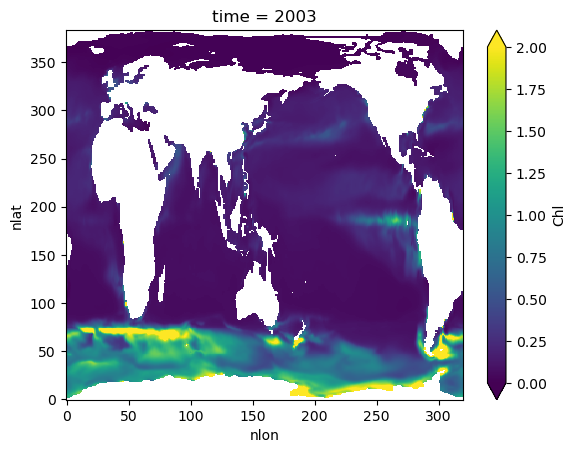

In [13]:
ds_DJF.Chl.isel(time=0).plot(vmin=0,vmax=2)

### MAM

In [14]:
ds.time[3].values

array(cftime.DatetimeNoLeap(2003, 3, 16, 12, 0, 0, 0, has_year_zero=True),
      dtype=object)

In [15]:
#%%time

years = np.arange(2003,2021+1,1)

tlen = len(years)
xlen = len(ds.nlon)
ylen = len(ds.nlat)

vars = ['Chl','IFRAC','TEMP']

for var in vars:

    MAM_mean = np.zeros([ylen, xlen, tlen])

    for year in np.arange(0,tlen,1):

        #get march for this year (data starts in Dec 2002 so index 3 is march)
        st_mon = year*12 + 3
        #print(year)
    
        i=0
        for month in [3,4,5]:
    
            if(month == 3):
                summing = ds[var].isel(time=st_mon) * days_per_month[month-1]
                tot_days = days_per_month[month-1]
            else:
                summing = summing + ds[var].isel(time=st_mon+i) * days_per_month[month-1]
                tot_days = tot_days + days_per_month[month-1]
    
            i = i + 1
    
        MAM_mean[:,:,year] = (summing/tot_days).compute()
    
    MAM_mean = xr.DataArray(MAM_mean,dims=('nlat','nlon','time'))
    
    ds_MAM[var] = MAM_mean

## fix time
ds_MAM['time'] = np.arange(2003,2022,1)

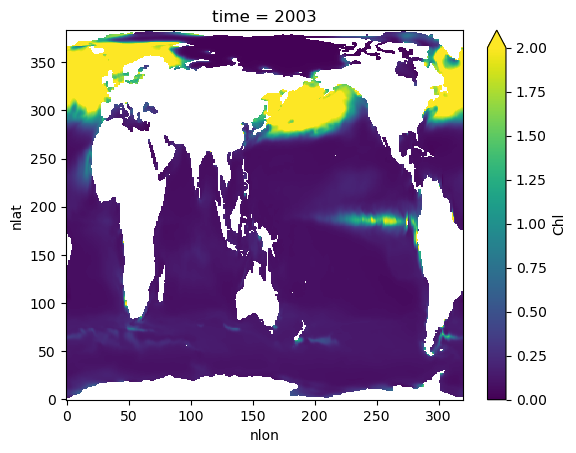

In [16]:
ds_MAM.Chl.isel(time=0).plot(vmin=0,vmax=2)

### JJA

In [17]:
ds.time[6].values

array(cftime.DatetimeNoLeap(2003, 6, 16, 0, 0, 0, 0, has_year_zero=True),
      dtype=object)

In [18]:
#%%time

years = np.arange(2003,2021+1,1)

tlen = len(years)
xlen = len(ds.nlon)
ylen = len(ds.nlat)

vars = ['Chl','IFRAC','TEMP']

for var in vars:

    JJA_mean = np.zeros([ylen, xlen, tlen])

    for year in np.arange(0,tlen,1):

        #get june for this year (data starts in Dec 2002 so index 6 is june)
        st_mon = year*12 + 6
        #print(year)
    
        i=0
        for month in [6,7,8]:
    
            if(month == 6):
                summing = ds[var].isel(time=st_mon) * days_per_month[month-1]
                tot_days = days_per_month[month-1]
            else:
                summing = summing + ds[var].isel(time=st_mon+i) * days_per_month[month-1]
                tot_days = tot_days + days_per_month[month-1]
    
            i = i + 1
    
        JJA_mean[:,:,year] = (summing/tot_days).compute()
    
    JJA_mean = xr.DataArray(JJA_mean,dims=('nlat','nlon','time'))
    
    ds_JJA[var] = JJA_mean

## fix time
ds_JJA['time'] = np.arange(2003,2022,1)

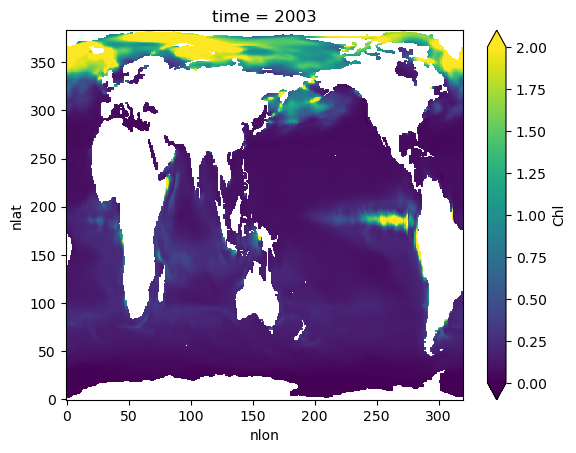

In [19]:
ds_JJA.Chl.isel(time=0).plot(vmin=0,vmax=2)

### SON

In [20]:
ds.time[9].values

array(cftime.DatetimeNoLeap(2003, 9, 16, 0, 0, 0, 0, has_year_zero=True),
      dtype=object)

In [21]:
#%%time

years = np.arange(2003,2021+1,1)

tlen = len(years)
xlen = len(ds.nlon)
ylen = len(ds.nlat)

vars = ['Chl','IFRAC','TEMP']

for var in vars:

    SON_mean = np.zeros([ylen, xlen, tlen])

    for year in np.arange(0,tlen,1):

        #get sept for this year 2003 (data starts in Dec 2002 so index 9 is sept)
        st_mon = year*12 + 9
        #print(year)
    
        i=0
        for month in [9,10,11]:
    
            if(month == 9):
                summing = ds[var].isel(time=st_mon) * days_per_month[month-1]
                tot_days = days_per_month[month-1]
            else:
                summing = summing + ds[var].isel(time=st_mon+i) * days_per_month[month-1]
                tot_days = tot_days + days_per_month[month-1]
    
            i = i + 1
    
        SON_mean[:,:,year] = (summing/tot_days).compute()
    
    SON_mean = xr.DataArray(SON_mean,dims=('nlat','nlon','time'))
    
    ds_SON[var] = SON_mean

## fix time
ds_SON['time'] = np.arange(2003,2022,1)

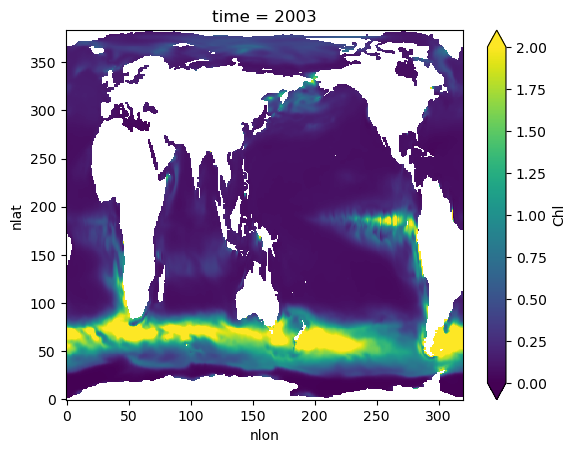

In [22]:
ds_SON.Chl.isel(time=0).plot(vmin=0,vmax=2)

## Looks good, now let's write out netcdfs

In [24]:
output_dir = '/glade/derecho/scratch/kristenk/INDEX_BGC_work'

ds_DJF.to_netcdf(output_dir + '/dsDJF_cesm_2003to2021.nc', mode='w')
ds_MAM.to_netcdf(output_dir + '/dsMAM_cesm_2003to2021.nc', mode='w')
ds_JJA.to_netcdf(output_dir + '/dsJJA_cesm_2003to2021.nc', mode='w')
ds_SON.to_netcdf(output_dir + '/dsSON_cesm_2003to2021.nc', mode='w')